# 122 · box-free normalizations: which level will work best?
Requirement levels (preferred first): **L4** no box knowledge (sample-only) · **L2** train stats pooled over all boxes · **L3** 5 empty scans of the box · **L1** full per-box stats (`--norm box`, reference).
nb121: box norm ≈ log(x/box mean)/CV (std ∝ mean), and its advantage is mostly conditioning, not information. So the log variants are the main box-free candidates.
Metrics per candidate: **box_acc** (logistic regression box classifier on the normalized pooled features, GroupKFold by position; lower = more box-invariant) and **box_var_frac** (between-box share of feature variance) · **cond** (per-feature std p95/p5) · **in-box probes** (ridge CoM / mask-PCA8 R², all boxes pooled, GroupKFold by position) · **cross-box transfer** (fit the probe on 2 boxes, test on the 3rd; stand-in for an unseen box).
x = linear |X| / sample std (src9 process_x, tukey). Loader and probes copied from nb121.

In [1]:
import sys, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
sys.path.insert(0, '..')
from src9.dataset import load_splits, load_fft
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score
plt.rcParams['figure.figsize'] = (18, 4.5)
samples, idxs = load_splits()
dirs, metas = list(samples), list(samples.values())

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

## 1 · load: 600 random train samples per box (as nb121) + up to 120 empty-box train scans per box (the calibration pool, kept apart)

In [2]:
rng = random.Random(0)
by_box, empt = {}, {}
for i in idxs['train']: by_box.setdefault(metas[i]['box'], []).append(i)
pick = sorted(sum([rng.sample(v, min(600, len(v))) for v in by_box.values()], []))
ps = set(pick)
for b, v in by_box.items():
    e = [i for i in v if metas[i]['n_objects'] == 0 and i not in ps]; empt[b] = sorted(rng.sample(e, min(120, len(e))))
print({b: len(v) for b, v in by_box.items()}, len(pick), {b: len(v) for b, v in empt.items()})
def load(i):
    x = load_fft(dirs[i], metas[i], 'tukey').abs()
    return (x / x.std()).numpy().astype(np.float32), np.asarray(Image.open(dirs[i] / 'image/03_smask.png').convert('F').resize((32, 32), Image.BOX), np.float32) / 255
with ThreadPoolExecutor(16) as ex: out = list(ex.map(load, pick))
X = np.stack([o[0] for o in out]); M = np.stack([o[1] for o in out]); del out
boxes = sorted(by_box)
with ThreadPoolExecutor(16) as ex: E = {b: np.stack([o[0] for o in ex.map(load, empt[b])]) for b in boxes}
def com(m, k): return m['coms'][0][0][k] / m['crop_overhead_shape'][k] if m['n_objects'] == 1 else np.nan
df = pd.DataFrame([dict(box=metas[i]['box'], exp=metas[i]['experiment'], pos=metas[i]['position_id'], spk=metas[i]['speaker'],
                        n_obj=metas[i]['n_objects'], com_r=com(metas[i], 0), com_c=com(metas[i], 1)) for i in pick])
S, L, F, Cc = X.shape; bidx = df.box.map({b: k for k, b in enumerate(boxes)}).values
print(X.shape, f'{(X.nbytes + sum(e.nbytes for e in E.values())) / 1e9:.2f} GB')

{'gastronorm': 2547, 'green-plastic': 3587, 'cardboard': 5085} 1800 {'gastronorm': 29, 'green-plastic': 53, 'cardboard': 65}


(1800, 100, 1170, 2) 1.82 GB


## 2 · candidates per level
L1 box mean/std (this subset, target-free as nb121). L2 pooled mean/std over all boxes (equal weight per box). L3: mean of k=5 random empty scans of that box (5 draws → calibration noise) or all its empties; std = std of those empties pooled over lasers per (f,c).

In [3]:
eps = 1e-6
lg = lambda x: np.log(x + 1e-3)
def sz(x): return (x - x.mean((1, 2, 3), keepdims=True)) / (x.std((1, 2, 3), keepdims=True) + eps)   # over the sample's (L,F,C)
def lz(x): return (x - x.mean(1, keepdims=True)) / (x.std(1, keepdims=True) + eps)                   # per (f,c) across lasers (src9 laser_z)
def dc(x): return x - x.mean(1, keepdims=True) - x.mean(2, keepdims=True) + x.mean((1, 2), keepdims=True)   # double-center over lasers & bins
BMU = np.stack([X[bidx == k].mean(0) for k in range(3)]); BSD = np.stack([X[bidx == k].std(0) for k in range(3)])
GMU = BMU.mean(0); GSD = np.sqrt((BSD ** 2 + (BMU - GMU) ** 2).mean(0))          # pooled over boxes (equal weight)
C = {  # name: (level, fn(x, box))
 'sample_z':        ('L4', lambda x, k: sz(x)),
 'laser_z':         ('L4', lambda x, k: lz(x)),
 'laser_bin_z':     ('L4', lambda x, k: (x - x.mean(2, keepdims=True)) / (x.std(2, keepdims=True) + eps)),   # per (l,c) z over bins
 'log_sample_z':    ('L4', lambda x, k: sz(lg(x))),
 'log_laser_z':     ('L4', lambda x, k: lz(lg(x))),
 'log_lasmean':     ('L4', lambda x, k: lg(x) - lg(x).mean(1, keepdims=True)),   # log ratio to this sample's own laser-mean spectrum
 'log_dc':          ('L4', lambda x, k: dc(lg(x))),
 'global':          ('L2', lambda x, k: (x - GMU) / GSD),
 'global_z':        ('L2', lambda x, k: sz((x - GMU) / GSD)),
 'log_global':      ('L2', lambda x, k: lg(x) - lg(GMU)),
 'log_global_z':    ('L2', lambda x, k: sz(lg(x) - lg(GMU))),
 'box (ref)':       ('L1', lambda x, k: (x - BMU[k]) / BSD[k]),
 'log_box':         ('L1', lambda x, k: lg(x) - lg(BMU[k])),
}
def l3(n, seed):
    r = np.random.default_rng(seed); mu, sd = [], []
    for b in boxes:
        e = E[b] if n is None else E[b][r.choice(len(E[b]), n, replace=False)]
        mu.append(e.mean(0)); sd.append(np.sqrt(((e - e.mean(0)) ** 2).mean((0, 1)))[None])
    mu, sd = np.stack(mu), np.stack(sd)          # (3,L,F,C), (3,1,F,C)
    return {'empty_z':     ('L3', lambda x, k: (x - mu[k]) / (sd[k] + eps)),
            'log_empty':   ('L3', lambda x, k: lg(x) - lg(mu[k])),
            'log_empty_z': ('L3', lambda x, k: sz(lg(x) - lg(mu[k])))}

## 3 · features (65-bin band means → 3,600) and the three tests

In [4]:
band = 65; nb = F // band
pool = lambda Z: Z[:, :, :nb * band].reshape(len(Z), L, nb, band, Cc).mean(3).reshape(len(Z), -1)
def featurize(fn):
    Fm = np.zeros((S, L * nb * Cc), np.float32)
    for k in range(3):
        ii = np.where(bidx == k)[0]
        for j in range(0, len(ii), 200): Fm[ii[j:j+200]] = pool(fn(X[ii[j:j+200]], k))
    return Fm
groups = (df.exp + '_' + df.pos.astype(str)).values
one, nonempty = np.where(df.n_obj == 1)[0], np.where(df.n_obj > 0)[0]
Y_com = df[['com_r', 'com_c']].values[one]; Mf = M.reshape(S, -1)[nonempty]
alphas = np.logspace(-3, 6, 19)
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas))
def fitpred(Ftr, Ytr, Fte, Yte, pca):
    if pca: p = PCA(8).fit(Ytr); Ytr, Yte = p.transform(Ytr), p.transform(Yte)
    return Yte, ridge().fit(Ftr, Ytr).predict(Fte)
def probe(Fm, rows, Y, pca=False):
    ys, ps = zip(*[fitpred(Fm[rows][tr], Y[tr], Fm[rows][te], Y[te], pca) for tr, te in GroupKFold(5).split(rows, groups=groups[rows])])
    return r2_score(np.concatenate(ys), np.concatenate(ps))
def cross_box(Fm):
    # fit on 2 boxes (scaler too), test on the 3rd -> R2 on the held-out box
    r = {}
    for k, b in enumerate(boxes):
        for nm, rows, Y, pca in [('com', one, Y_com, False), ('mask8', nonempty, Mf, True)]:
            tr, te = bidx[rows] != k, bidx[rows] == k
            r[f'{nm}_{b}'] = r2_score(*fitpred(Fm[rows][tr], Y[tr], Fm[rows][te], Y[te], pca))
    return r
def box_leak(Fm):
    acc = []
    for tr, te in GroupKFold(5).split(Fm, groups=groups):
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1e-4, max_iter=300)).fit(Fm[tr], bidx[tr]); acc.append((m.predict(Fm[te]) == bidx[te]).mean())
    gm = Fm.mean(0); tot = ((Fm - gm) ** 2).sum(dtype=np.float64)
    between = sum((bidx == k).sum() * ((Fm[bidx == k].mean(0) - gm) ** 2).sum(dtype=np.float64) for k in range(3))
    return np.mean(acc), between / tot
def evaluate(name, level, fn, draw=None):
    Fm = featurize(fn); acc, bv = box_leak(Fm); cb = cross_box(Fm); sd = Fm.std(0)
    return dict(name=name, level=level, draw=draw, box_acc=acc, box_var_frac=bv, cond=np.percentile(sd, 95) / np.percentile(sd, 5),
                com_R2=probe(Fm, one, Y_com), mask8_R2=probe(Fm, nonempty, Mf, True),
                xbox_com_R2=np.mean([cb[f'com_{b}'] for b in boxes]), xbox_mask8_R2=np.mean([cb[f'mask8_{b}'] for b in boxes]), **{f'xcom_{b}': cb[f'com_{b}'] for b in boxes})
import time; t0 = time.time(); rows = []
for n, (lv, fn) in C.items(): rows.append(evaluate(n, lv, fn)); print(f'{n:14s} {time.time() - t0:5.0f}s', {k: round(v, 3) for k, v in rows[-1].items() if isinstance(v, float)})
for n, (lv, fn) in l3(None, 0).items(): rows.append(evaluate(n + ' [all]', lv, fn))
for seed in range(5):
    for n, (lv, fn) in l3(5, seed).items(): rows.append(evaluate(n + ' [5]', lv, fn, seed))
print(f'done {time.time() - t0:.0f}s')
R = pd.DataFrame(rows)

sample_z          21s {'box_acc': np.float64(1.0), 'box_var_frac': np.float64(0.849), 'com_R2': 0.718, 'mask8_R2': 0.522, 'xbox_com_R2': np.float64(-16.851), 'xbox_mask8_R2': np.float64(-30.57), 'xcom_cardboard': -27.857, 'xcom_gastronorm': -2.532, 'xcom_green-plastic': -20.165}


laser_z           48s {'box_acc': np.float64(1.0), 'box_var_frac': np.float64(0.567), 'com_R2': 0.699, 'mask8_R2': 0.506, 'xbox_com_R2': np.float64(-4.46), 'xbox_mask8_R2': np.float64(-8.955), 'xcom_cardboard': -7.137, 'xcom_gastronorm': -0.702, 'xcom_green-plastic': -5.541}


laser_bin_z       68s {'box_acc': np.float64(1.0), 'box_var_frac': np.float64(0.698), 'com_R2': 0.702, 'mask8_R2': 0.512, 'xbox_com_R2': np.float64(-22.809), 'xbox_mask8_R2': np.float64(-27.231), 'xcom_cardboard': -20.927, 'xcom_gastronorm': -8.963, 'xcom_green-plastic': -38.537}


log_sample_z      86s {'box_acc': np.float64(1.0), 'box_var_frac': np.float64(0.611), 'com_R2': 0.704, 'mask8_R2': 0.535, 'xbox_com_R2': np.float64(-4.804), 'xbox_mask8_R2': np.float64(-11.402), 'xcom_cardboard': -1.046, 'xcom_gastronorm': -10.679, 'xcom_green-plastic': -2.689}


log_laser_z      113s {'box_acc': np.float64(1.0), 'box_var_frac': np.float64(0.54), 'com_R2': 0.703, 'mask8_R2': 0.527, 'xbox_com_R2': np.float64(-2.365), 'xbox_mask8_R2': np.float64(-6.927), 'xcom_cardboard': -1.164, 'xcom_gastronorm': -2.729, 'xcom_green-plastic': -3.203}


log_lasmean      134s {'box_acc': np.float64(1.0), 'box_var_frac': np.float64(0.563), 'com_R2': 0.708, 'mask8_R2': 0.527, 'xbox_com_R2': np.float64(-2.721), 'xbox_mask8_R2': np.float64(-9.797), 'xcom_cardboard': -2.502, 'xcom_gastronorm': -3.261, 'xcom_green-plastic': -2.399}


... (4 outputs left out)

log_global_z     229s {'box_acc': np.float64(1.0), 'box_var_frac': np.float64(0.6), 'com_R2': 0.697, 'mask8_R2': 0.531, 'xbox_com_R2': np.float64(-3.642), 'xbox_mask8_R2': np.float64(-14.837), 'xcom_cardboard': -0.696, 'xcom_gastronorm': -7.587, 'xcom_green-plastic': -2.643}


box (ref)        253s {'box_acc': np.float64(0.242), 'box_var_frac': np.float64(0.0), 'com_R2': 0.726, 'mask8_R2': 0.542, 'xbox_com_R2': np.float64(-1.093), 'xbox_mask8_R2': np.float64(-1.467), 'xcom_cardboard': -0.49, 'xcom_gastronorm': -0.471, 'xcom_green-plastic': -2.32}


log_box          289s {'box_acc': np.float64(0.956), 'box_var_frac': np.float64(0.01), 'com_R2': 0.708, 'mask8_R2': 0.548, 'xbox_com_R2': np.float64(-1.175), 'xbox_mask8_R2': np.float64(-2.006), 'xcom_cardboard': -0.906, 'xcom_gastronorm': -0.564, 'xcom_green-plastic': -2.056}


done 1145s


## 4 · ranked table
Sorted by cross-box CoM R² (the unseen-box stand-in). L3 [5] rows = mean over 5 random 5-scan draws, `*_sd` = sd over draws (calibration noise). `score` = com + mask8 + xbox_com + xbox_mask8.

In [5]:
cols = ['box_acc', 'box_var_frac', 'cond', 'com_R2', 'mask8_R2', 'xbox_com_R2', 'xbox_mask8_R2'] + [f'xcom_{b}' for b in boxes]
agg = R.groupby(['level', 'name'], sort=False)[cols].mean()
sd = R[R.draw.notna()].groupby(['level', 'name'])[['com_R2', 'mask8_R2', 'xbox_com_R2', 'xbox_mask8_R2']].std().add_suffix('_sd')
T = agg.join(sd); T['score'] = T.com_R2 + T.mask8_R2 + T.xbox_com_R2 + T.xbox_mask8_R2
T = T.sort_values('xbox_com_R2', ascending=False).round(3)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
T

box_acc  box_var_frac    cond  com_R2  mask8_R2  xbox_com_R2  xbox_mask8_R2  xcom_cardboard  xcom_gastronorm  xcom_green-plastic  com_R2_sd  mask8_R2_sd  xbox_com_R2_sd  xbox_mask8_R2_sd   score
level name                                                                                                                                                                                                                 
L1    box (ref)            0.242         0.000   1.643   0.726     0.542       -1.093         -1.467          -0.490           -0.471              -2.320        NaN          NaN             NaN               NaN  -1.292
      log_box              0.956         0.010   2.390   0.708     0.548       -1.175         -2.006          -0.906           -0.564              -2.056        NaN          NaN             NaN               NaN  -1.925
L3    log_empty_z [all]    0.994         0.048   2.345   0.715     0.559       -1.208         -2.192          -1.125           -0.582              -1.917        NaN          NaN             NaN               NaN  -2.126
      log_empty [all]      0.992         0.052   2.390   0.707     0.549       -1.224         -2.118          -1.047           -0.555              -2.069        NaN          NaN             NaN               NaN  -2.085
      log_empty_z [5]      0.997         0.124   2.399   0.722     0.555       -1.328         -2.396          -1.339           -0.662              -1.981      0.007        0.002           0.112             0.117  -2.447
      log_empty [5]        0.996         0.156   2.497   0.714     0.544       -1.389         -2.418          -1.176           -0.604              -2.387      0.002        0.002           0.189             0.214  -2.549
L4    log_laser_z          1.000         0.540   2.788   0.703     0.527       -2.365         -6.927          -1.164           -2.729              -3.203        NaN          NaN             NaN               NaN  -8.062
      log_lasmean          1.000         0.563   2.754   0.708     0.527       -2.721         -9.797          -2.502           -3.261              -2.399        NaN          NaN             NaN               NaN -11.283
L3    empty_z [all]        0.982         0.053   2.913   0.725     0.527       -2.955         -3.761          -1.399           -0.412              -7.055        NaN          NaN             NaN               NaN  -5.464
L2    log_global           1.000         0.601   2.296   0.702     0.535       -3.582        -10.924          -0.782           -2.721              -7.243        NaN          NaN             NaN               NaN -13.270
      log_global_z         1.000         0.600   2.344   0.697     0.531       -3.642        -14.837          -0.696           -7.587              -2.643        NaN          NaN             NaN               NaN -17.250
L4    laser_z              1.000         0.567   3.241   0.699     0.506       -4.460         -8.955          -7.137           -0.702              -5.541        NaN          NaN             NaN               NaN -12.211
      log_sample_z         1.000         0.611   2.355   0.704     0.535       -4.804        -11.402          -1.046          -10.679              -2.689        NaN          NaN             NaN               NaN -14.968
L2    global_z             1.000         0.503   1.580   0.719     0.539       -5.202        -14.142          -3.537           -1.367             -10.702        NaN          NaN             NaN               NaN -18.085
L4    log_dc               1.000         0.489   2.454   0.679     0.527       -5.215         -6.122          -2.487           -5.741              -7.418        NaN          NaN             NaN               NaN -10.131
L3    empty_z [5]          0.990         0.185   3.543   0.696     0.507       -7.221        -12.467          -1.247           -0.712             -19.703      0.054        0.040           7.520            13.850 -18.484
L4    sample_z             1.000         0.849  15.799   0.718   

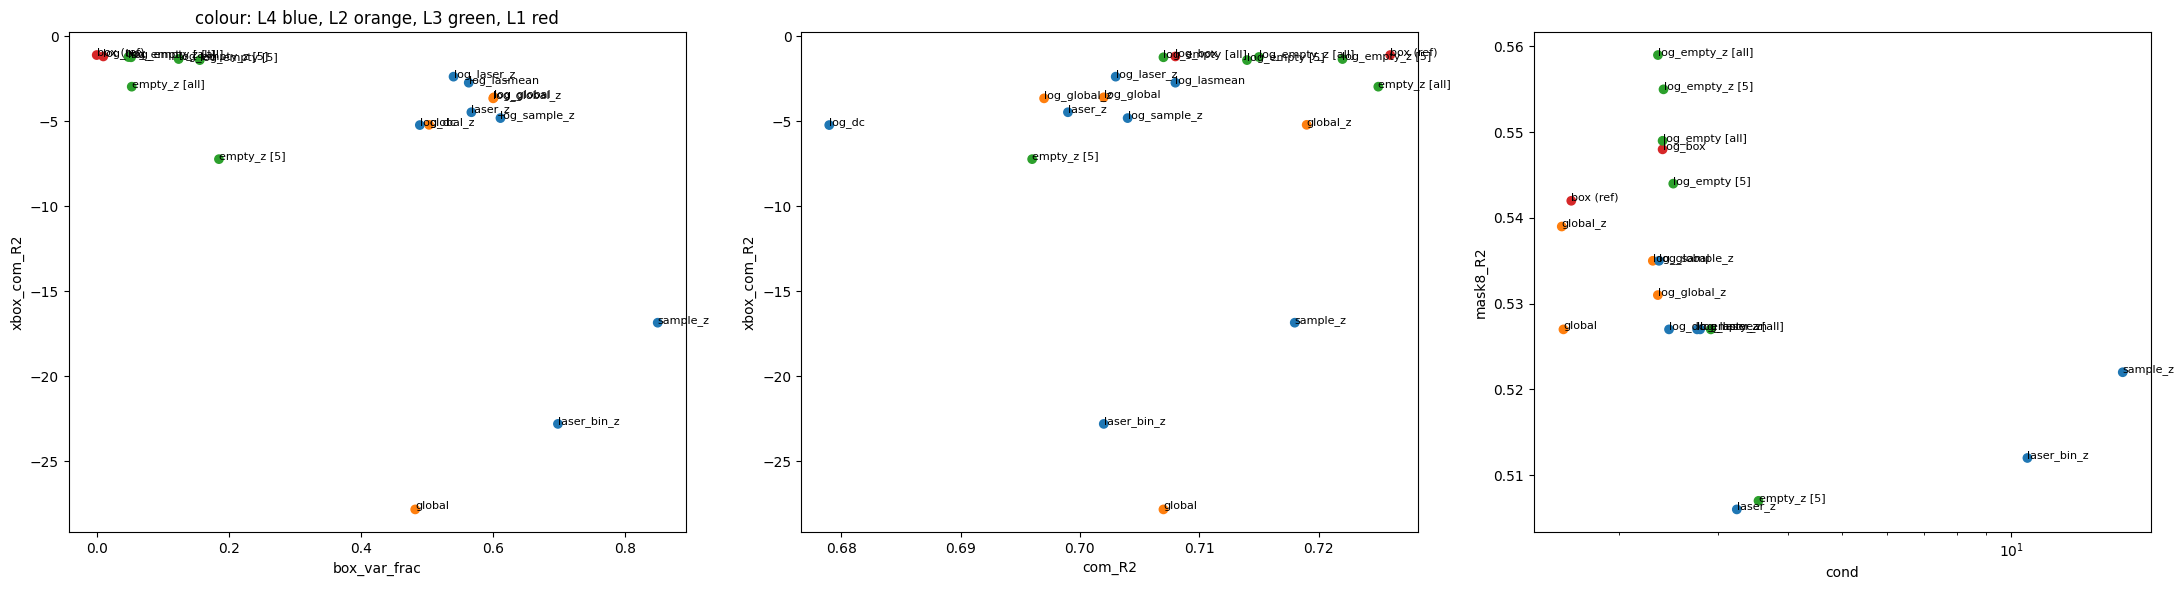

best per level (by score = com + mask8 + xbox_com + xbox_mask8):
L4
       name  cond  com_R2  mask8_R2  xbox_com_R2  xbox_mask8_R2  box_acc   score
log_laser_z 2.788   0.703     0.527       -2.365         -6.927      1.0  -8.062
     log_dc 2.454   0.679     0.527       -5.215         -6.122      1.0 -10.131
log_lasmean 2.754   0.708     0.527       -2.721         -9.797      1.0 -11.283
L2
        name  cond  com_R2  mask8_R2  xbox_com_R2  xbox_mask8_R2  box_acc   score
  log_global 2.296   0.702     0.535       -3.582        -10.924      1.0 -13.270
log_global_z 2.344   0.697     0.531       -3.642        -14.837      1.0 -17.250
    global_z 1.580   0.719     0.539       -5.202        -14.142      1.0 -18.085
L3
             name  cond  com_R2  mask8_R2  xbox_com_R2  xbox_mask8_R2  box_acc  score
  log_empty [all] 2.390   0.707     0.549       -1.224         -2.118    0.992 -2.085
log_empty_z [all] 2.345   0.715     0.559       -1.208         -2.192    0.994 -2.126
  log_empty_z [5

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(22, 6))
T2 = T.reset_index(); colr = T2.level.map({'L4': 'C0', 'L2': 'C1', 'L3': 'C2', 'L1': 'C3'})
for a, (xc, yc) in zip(ax, [('box_var_frac', 'xbox_com_R2'), ('com_R2', 'xbox_com_R2'), ('cond', 'mask8_R2')]):
    a.scatter(T2[xc], T2[yc], c=colr)
    for _, r in T2.iterrows(): a.annotate(r['name'], (r[xc], r[yc]), fontsize=8)
    a.set(xlabel=xc, ylabel=yc)
ax[2].set_xscale('log'); ax[0].set_title('colour: L4 blue, L2 orange, L3 green, L1 red'); plt.tight_layout(); plt.show()
print('best per level (by score = com + mask8 + xbox_com + xbox_mask8):')
for lv in ['L4', 'L2', 'L3', 'L1']:
    print(lv); print(T2[T2.level == lv].sort_values('score', ascending=False)[['name', 'cond', 'com_R2', 'mask8_R2', 'xbox_com_R2', 'xbox_mask8_R2', 'box_acc', 'score']].head(3).to_string(index=False))

## summary
1800 train samples (600 per box). Empty-scan calibration pools hold 29 (gastro), 53 (plastic) and 65 (cardboard) train scans. Runtime is about 19 min.
- **In-box information is flat again** (as in nb121): CoM R² .68–.73 and mask8 .51–.56 for every candidate. In-box probes can't separate the candidates.
- **Box invariance needs box information.** The logistic box classifier gets 1.00 for every L4 and L2 candidate, .99 for L3, .96 for log_box, and .24 for box (ref). The between-box variance fraction is the graded version: L4/L2 .48–.85; L3 log_empty .05 with all empties and .12–.16 with 5 scans; L1 ≈ 0.
- **Cross-box transfer** (ridge fit on 2 boxes, scored on the 3rd) is **negative for every candidate**, including box (ref) at −1.09 CoM. A linear laser-pattern→position map does not carry over to a new box, even after box normalization, so this metric only measures how badly predictions blow up off-distribution. On that scale the **linear** box-free norms are catastrophic: sample_z −16.9, global −27.8, laser_bin_z −22.8. **Log** variants are 2–7× less bad: log_laser_z −2.4, log_lasmean −2.7, log_global −3.6. log_empty with 5 scans (−1.33 ± .11) is about as good as the box stats (−1.09 / −1.18).
- **Conditioning** (p95/p5 of per-feature std): every log variant is 2.3–2.8×, close to box_z at 1.6×, against sample_z 16× and laser_bin_z 11×. global and global_z reach 1.6× but transfer badly.
- **L3 calibration noise** from 5-scan draws is small for log_empty (xbox sd .11–.19, in-box sd ≤ .007). For the linear empty_z it is huge (xbox −7.2 ± 7.5), because a 5-scan std is too noisy to divide by. The log form needs only the empty mean.
- **Best per level:** L4 **log_laser_z** (log|x| then z across lasers per (f,c)) · L2 **log_global** (log(x/pooled mean); a sample z after it doesn't help) · L3 **log_empty** (log(x / mean of 5 empty scans)) · L1 box (ref) ≈ log_box.
- **Take-away:** the log is the transferable part of box norm. log_laser_z keeps box_z's conditioning without box stats, and it removes the per-sample laser-mean spectrum (drift), which nb121 showed carries little CoM.
- **Training runs to try:** `--norm log_laser_z` (L4, first choice) and `--norm log_empty5` (L3). Compare on ID IoU against box .623 and laser_z .584, and on any held-out-box split.